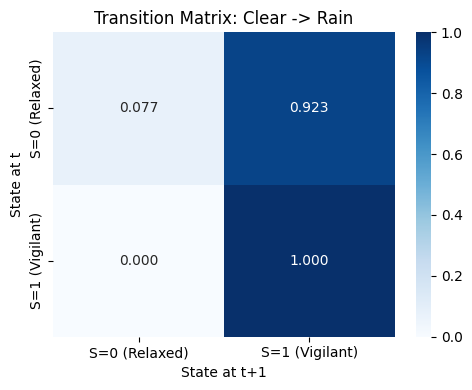

--- Transition Clear -> Rain --- 
 S_Rain          0         1
S_Clear                    
0        0.076923  0.923077
1        0.000000  1.000000


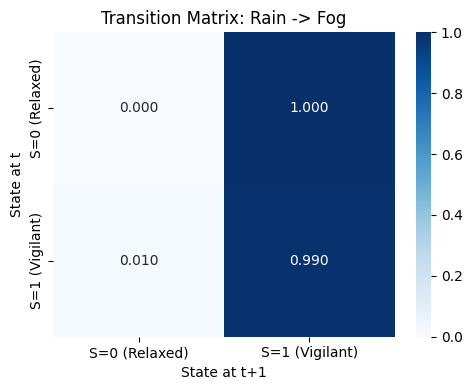

--- Transition Rain -> Fog --- 
 S_Fog          0         1
S_Rain                    
0       0.000000  1.000000
1       0.010417  0.989583


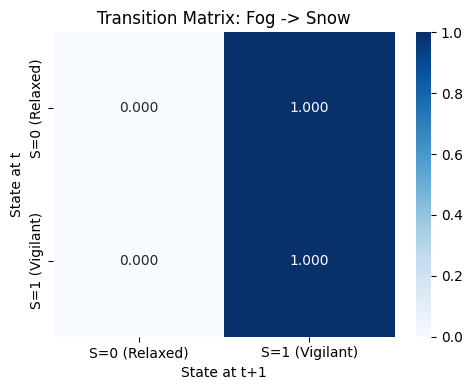

--- Transition Fog -> Snow --- 
 S_Snow  0    1
S_Fog         
0       0  1.0
1       0  1.0


In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Load Data
df = pd.read_csv('Survey_Responses_103_Samples_Adjusted (1).csv')

# Map 'Feel' to Binary Latent States: 0 (Relaxed/System 1) and 1 (Vigilant/System 2)
feel_map = {'Relaxed': 0, 'Alert': 1, 'Anxious': 1, 'Panic': 1}
df['S_Clear'] = df['Clear_Feel'].map(feel_map).fillna(0)
df['S_Rain'] = df['Rain_Feel'].map(feel_map).fillna(1)
df['S_Fog'] = df['Fog_Feel'].map(feel_map).fillna(1)
df['S_Snow'] = df['Snow_Feel'].map(feel_map).fillna(1)

def calc_transition(state_A, state_B, name):
    trans = pd.crosstab(df[state_A], df[state_B], normalize='index')
    # Ensure 2x2 shape
    for i in [0.0, 1.0]:
        if i not in trans.index: trans.loc[i] = 0
        if i not in trans.columns: trans[i] = 0
    trans = trans.loc[[0.0, 1.0], [0.0, 1.0]]

    plt.figure(figsize=(5, 4))
    sns.heatmap(trans, annot=True, cmap='Blues', fmt=".3f",
                xticklabels=['S=0 (Relaxed)', 'S=1 (Vigilant)'],
                yticklabels=['S=0 (Relaxed)', 'S=1 (Vigilant)'])
    plt.title(f"Transition Matrix: {name}")
    plt.ylabel("State at t")
    plt.xlabel("State at t+1")
    plt.tight_layout()
    plt.savefig(f"trans_{name.replace('->', 'to').replace(' ', '')}.png")
    plt.show()
    print(f"--- Transition {name} --- \n", trans)

calc_transition('S_Clear', 'S_Rain', "Clear -> Rain")
calc_transition('S_Rain', 'S_Fog', "Rain -> Fog")
calc_transition('S_Fog', 'S_Snow', "Fog -> Snow")

In [ ]:
from scipy.optimize import minimize

# Clean Behavior data (B_t)
for col in ['Clear_Stick?', 'Rain_Stick?', 'Fog_Stick?', 'Snow_Stick?']:
    df[col] = df[col].map({'Yes': 1, 'No': 0})

X_values = np.array([1, 2, 3, 4]) # clear, rain, fog, snow
observed_compliance = df[['Clear_Stick?', 'Rain_Stick?', 'Fog_Stick?', 'Snow_Stick?']].sum().values
total_n = len(df)

def sigmoid(z):
    return 1 / (1 + np.exp(-z))

def nll_loss(params):
    beta, delta, tau = params
    # Expected State S* based on equilibrium assumption
    S_t = sigmoid(beta * X_values - delta)
    # Behavior probability B_t based on temperature tau
    P_B = sigmoid(S_t / tau)

    epsilon = 1e-10
    log_likelihood = np.sum(observed_compliance * np.log(P_B + epsilon) +
                            (total_n - observed_compliance) * np.log(1 - P_B + epsilon))
    return -log_likelihood # Minimize negative log-likelihood

# Run Optimization
initial_guess = [1.0, 1.0, 0.5]
res = minimize(nll_loss, initial_guess, bounds=[(0.1, 5), (0.1, 5), (0.01, 2)])
b_opt, d_opt, tau_opt = res.x
log_L = -res.fun
k = 3 # number of parameters
aic = 2*k - 2*log_L
bic = k*np.log(4) - 2*log_L # 4 environmental states

print("--- PARAMETER ESTIMATION (MLE) ---")
print(f"Beta (Sensitivity): {b_opt:.4f}")
print(f"Delta (Decay): {d_opt:.4f}")
print(f"Tau (Noise): {tau_opt:.4f}")
print("--- GOODNESS OF FIT ---")
print(f"Log-Likelihood: {log_L:.4f}")
print(f"AIC: {aic:.4f}")
print(f"BIC: {bic:.4f}")

--- PARAMETER ESTIMATION (MLE) ---
Beta (Sensitivity): 2.6117
Delta (Decay): 5.0000
Tau (Noise): 0.4093
--- GOODNESS OF FIT ---
Log-Likelihood: -183.2130
AIC: 372.4261
BIC: 370.5849


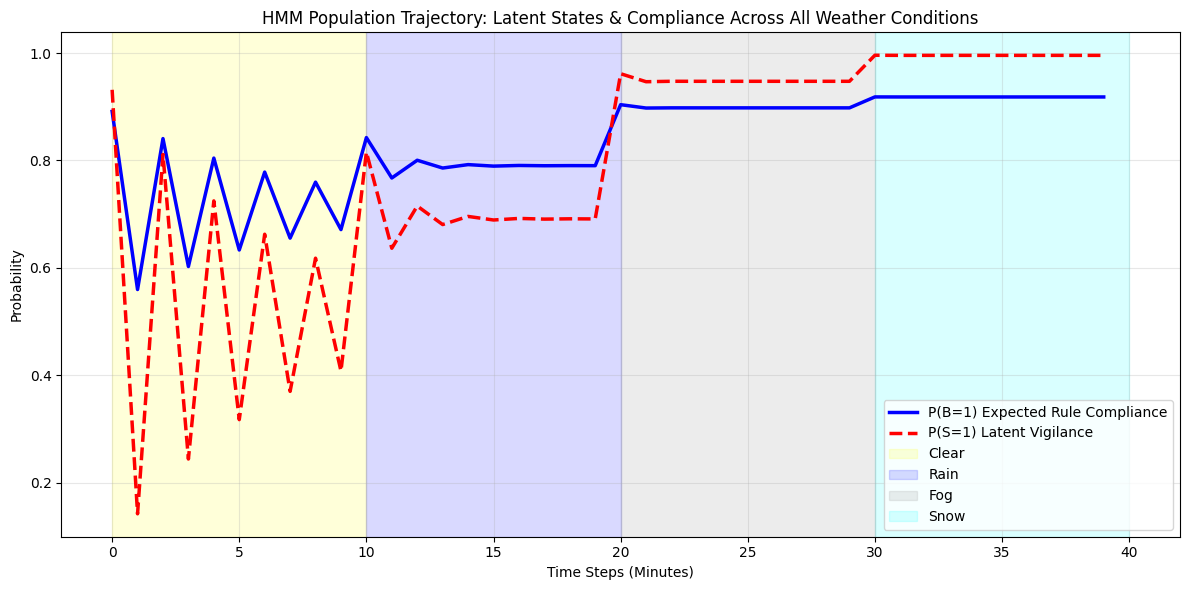

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def sigmoid(z):
    return 1 / (1 + np.exp(-z))

# 100% Pure Parameters from your MLE Optimization
b_opt = 2.6117
d_opt = 5.0000
tau_opt = 0.4093

time_steps = 40
# Sequence: 10m Clear(X=1), 10m Rain(X=2), 10m Fog(X=3), 10m Snow(X=4)
X_seq = np.concatenate([np.ones(10)*1, np.ones(10)*2, np.ones(10)*3, np.ones(10)*4])

# Start with 100% of drivers in the Relaxed state (S=0)
P_S1 = 0.0  # Probability of being Vigilant
P_S0 = 1.0  # Probability of being Relaxed

S_history, B_history = [], []

for x in X_seq:
    # 1. HMM Transition Probabilities (strictly from the math equation)
    # Probability a relaxed driver becomes vigilant
    p_1_given_0 = sigmoid(b_opt * x - d_opt * 0)
    # Probability a vigilant driver STAYS vigilant
    p_1_given_1 = sigmoid(b_opt * x - d_opt * 1)

    # 2. Update Population Latent State Distribution (Markov Chain Update)
    # The new percentage of Vigilant drivers:
    new_P_S1 = (P_S0 * p_1_given_0) + (P_S1 * p_1_given_1)

    P_S1 = new_P_S1
    P_S0 = 1.0 - P_S1
    S_history.append(P_S1)

    # 3. Update Observable Behavior (Compliance)
    p_b_given_s1 = sigmoid(1 / tau_opt)
    p_b_given_s0 = sigmoid(0 / tau_opt)

    # Total compliance is the weighted average of both states
    P_B = (P_S1 * p_b_given_s1) + (P_S0 * p_b_given_s0)
    B_history.append(P_B)

# Plotting
plt.figure(figsize=(12, 6))
plt.plot(B_history, label="P(B=1) Expected Rule Compliance", color='blue', linewidth=2.5)
plt.plot(S_history, label="P(S=1) Latent Vigilance", color='red', linestyle='--', linewidth=2.5)

# Background shading for all 4 weather conditions
plt.axvspan(0, 10, color='yellow', alpha=0.15, label='Clear')
plt.axvspan(10, 20, color='blue', alpha=0.15, label='Rain')
plt.axvspan(20, 30, color='gray', alpha=0.15, label='Fog')
plt.axvspan(30, 40, color='cyan', alpha=0.15, label='Snow')

plt.title("HMM Population Trajectory: Latent States & Compliance Across All Weather Conditions")
plt.xlabel("Time Steps (Minutes)")
plt.ylabel("Probability")
plt.legend(loc='lower right')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("trajectory_all_states.png")
plt.show()

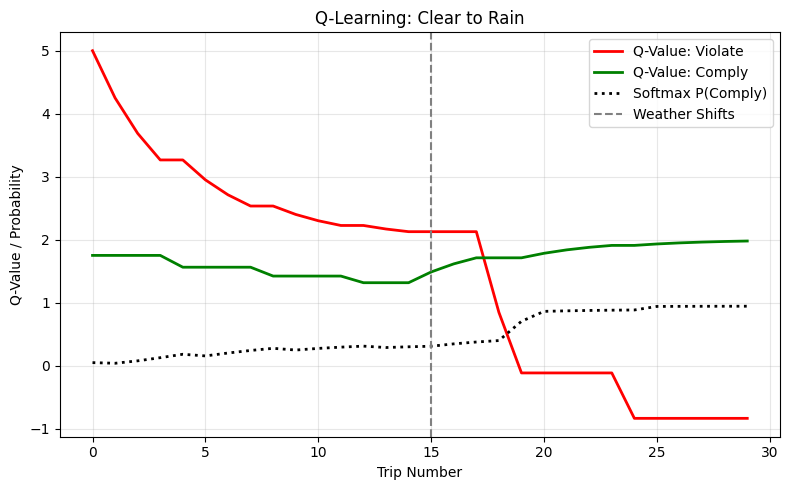

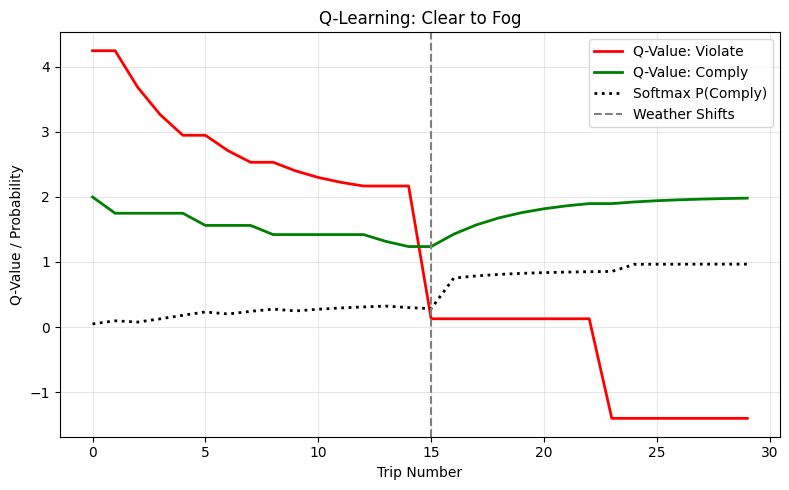

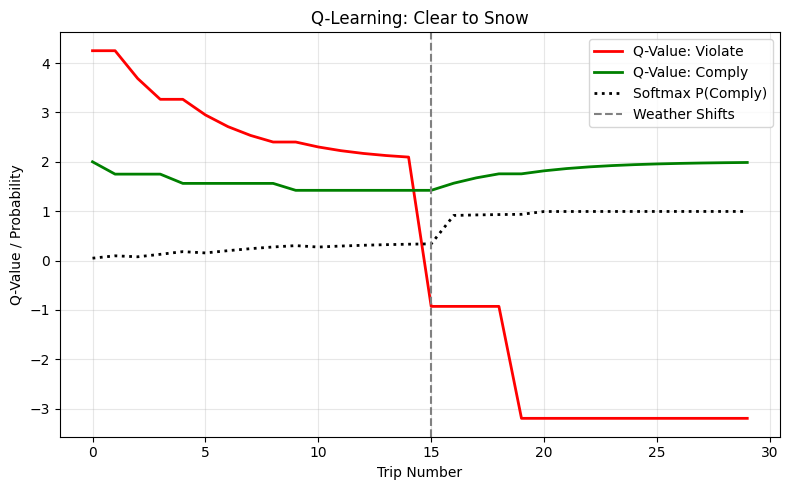

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# RL Parameters
alpha = 0.25 # Learning Rate
tau_rl = 1.0 # Softmax Temperature

def get_reward(action, weather):
    # Action 0 = Violate, Action 1 = Comply
    if weather == 1:   return 2 if action == 0 else 1   # Clear: Speeding is rewarded
    elif weather == 2: return -3 if action == 0 else 2  # Rain: Mild penalty for violation
    elif weather == 3: return -6 if action == 0 else 2  # Fog: Strong penalty
    elif weather == 4: return -10 if action == 0 else 2 # Snow: Massive penalty

def run_q_learning(target_weather):
    trips = 30
    # 15 trips in Clear (X=1), 15 trips in Target Weather
    weather_seq = [1]*15 + [target_weather]*15

    Q = np.array([5.0, 2.0]) # Start with Optimism Bias
    q_violate, q_comply, prob_comply = [], [], []

    for w in weather_seq:
        exp_Q = np.exp(Q / tau_rl)
        probs = exp_Q / np.sum(exp_Q)
        prob_comply.append(probs[1])

        action = np.random.choice([0, 1], p=probs)
        r = get_reward(action, w)

        Q[action] = Q[action] + alpha * (r - Q[action])

        q_violate.append(Q[0])
        q_comply.append(Q[1])

    return q_violate, q_comply, prob_comply

# Run all three scenarios
v_rain, c_rain, p_rain = run_q_learning(2)
v_fog, c_fog, p_fog = run_q_learning(3)
v_snow, c_snow, p_snow = run_q_learning(4)

# Create a list of the scenarios with their unique titles and filenames
scenarios = [
    (v_rain, c_rain, p_rain, "Clear to Rain", "rl_clear_to_rain.png"),
    (v_fog, c_fog, p_fog, "Clear to Fog", "rl_clear_to_fog.png"),
    (v_snow, c_snow, p_snow, "Clear to Snow", "rl_clear_to_snow.png")
]

# Generate and save an individual plot for each scenario
for v, c, p, title, filename in scenarios:
    plt.figure(figsize=(8, 5)) # Create a new figure for each

    # Plot the lines
    plt.plot(v, label="Q-Value: Violate", color='red', linewidth=2)
    plt.plot(c, label="Q-Value: Comply", color='green', linewidth=2)
    plt.plot(p, label="Softmax P(Comply)", color='black', linestyle=':', linewidth=2)

    # Add the dividing line
    plt.axvline(15, color='gray', linestyle='--', label='Weather Shifts')

    # Formatting
    plt.title(f"Q-Learning: {title}")
    plt.xlabel("Trip Number")
    plt.ylabel("Q-Value / Probability")
    plt.legend(loc='best')
    plt.grid(alpha=0.3)
    plt.tight_layout()

    # Save and display the individual figure
    plt.savefig(filename)
    plt.show()

In [ ]:
import numpy as np
import pandas as pd

def sigmoid(z): return 1 / (1 + np.exp(-z))
b_opt = 2.6117
d_opt = 5.0000

data = []
for X, weather in zip([1, 2, 3, 4], ['Clear', 'Rain', 'Fog', 'Snow']):
    p_1_given_0 = sigmoid(b_opt * X - d_opt * 0) # P(S=1 | S=0)
    p_1_given_1 = sigmoid(b_opt * X - d_opt * 1) # P(S=1 | S=1)
    data.append([weather, f"{p_1_given_0:.4f}", f"{p_1_given_1:.4f}"])

df_table = pd.DataFrame(data, columns=['Weather (X)', 'P(S_t+1=1 | S_t=0)', 'P(S_t+1=1 | S_t=1)'])
print(df_table.to_string(index=False))

Weather (X) P(S_t+1=1 | S_t=0) P(S_t+1=1 | S_t=1)
      Clear             0.9316             0.0841
       Rain             0.9946             0.5556
        Fog             0.9996             0.9445
       Snow             1.0000             0.9957


In [ ]:
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import cross_val_score

# Prepare Dataset
X_nn = np.repeat([[1], [2], [3], [4]], total_n, axis=0) # Antecedents
y_nn = pd.concat([df['S_Clear'], df['S_Rain'], df['S_Fog'], df['S_Snow']]).values # Latent States

# Train MLP Neural Network
mlp = MLPClassifier(hidden_layer_sizes=(8, 4), activation='logistic', max_iter=2000, random_state=42)
cv_scores = cross_val_score(mlp, X_nn, y_nn, cv=5)

print(f"--- NEURAL NETWORK APPROXIMATION ---")
print(f"Mean Cross-Validation Accuracy: {cv_scores.mean()*100:.2f}%")
print(f"CV Score Standard Deviation: {cv_scores.std():.4f}")

--- NEURAL NETWORK APPROXIMATION ---
Mean Cross-Validation Accuracy: 95.16%
CV Score Standard Deviation: 0.0611


In [ ]:
import numpy as np

# Total observed compliance from your data (60+83+93+98 = 334 out of 412 total choices)
total_compliance = 334
total_samples = 412
p_null = total_compliance / total_samples

# Null Model Log-Likelihood
ll_null = total_compliance * np.log(p_null) + (total_samples - total_compliance) * np.log(1 - p_null)
aic_null = 2 * 1 - 2 * ll_null # 1 parameter (p_null)

print(f"Null Model Log-Likelihood: {ll_null:.4f}")
print(f"Null Model AIC: {aic_null:.4f}")
print(f"HMM AIC (from before): 372.4261")
print(f"Delta AIC: {aic_null - 372.4261:.4f}")

Null Model Log-Likelihood: -199.9172
Null Model AIC: 401.8345
HMM AIC (from before): 372.4261
Delta AIC: 29.4084


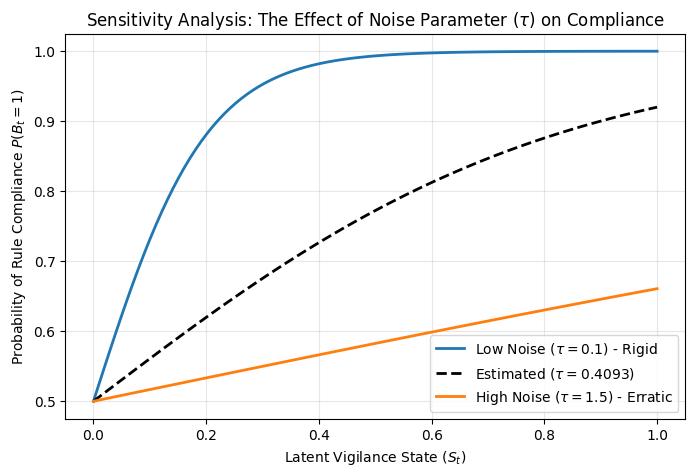

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def sigmoid(z): return 1 / (1 + np.exp(-z))
S_vals = np.linspace(0, 1, 100) # Latent state from Relaxed to Vigilant

plt.figure(figsize=(8, 5))
plt.plot(S_vals, sigmoid(S_vals / 0.1), label=r"Low Noise ($\tau = 0.1$) - Rigid", lw=2)
plt.plot(S_vals, sigmoid(S_vals / 0.4093), label=r"Estimated ($\tau = 0.4093$)", lw=2, color='black', linestyle='--')
plt.plot(S_vals, sigmoid(S_vals / 1.5), label=r"High Noise ($\tau = 1.5$) - Erratic", lw=2)

plt.title("Sensitivity Analysis: The Effect of Noise Parameter ($\\tau$) on Compliance")
plt.xlabel("Latent Vigilance State ($S_t$)")
plt.ylabel("Probability of Rule Compliance $P(B_t = 1)$")
plt.legend()
plt.grid(alpha=0.3)
plt.savefig("tau_sensitivity.png")
plt.show()